# Developing a Data Analysis and Machine Learning Workflow Using WHO Sri Lanka Health Indicators

**Focused indicator:** Stunting prevalence among children under 5 years of age (% height-for-age < −2 SD), survey-based estimates  
**Programme:** HND in Computer Science with Artificial Intelligence — NIBM KIC  
**Module:** Numerical Mathematics and Computing  
**Group:** 03
*   KIC-HNDCSAI-261P-002
*   KIC-HNDCSAI-261P-006

**Dataset:** WHO data for Sri Lanka, provided through the Humanitarian Data Exchange (HDX)

## Notebook purpose
This notebook includes data cleaning, preprocessing, four EDA visualizations, two hypothesis tests, and two regression models.

The results are for academic coursework and exploratory analysis only. They are not intended for clinical decision-making.

## 1. Import libraries

The notebook uses pandas and NumPy for data handling, Matplotlib and Seaborn for visualizations, SciPy for hypothesis testing, and scikit-learn for preprocessing and regression models.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ALPHA = 0.05

## 2. Load the dataset



In [2]:
DATA_PATH = "health_indicators_lka(4)(1).csv"
raw_df = pd.read_csv(DATA_PATH)

print("Original dataset shape:", raw_df.shape)
display(raw_df.head())
display(raw_df.info())

Original dataset shape: (30912, 17)


,GHO (CODE),GHO (DISPLAY),GHO (URL),YEAR (DISPLAY),STARTYEAR,ENDYEAR,REGION (CODE),REGION (DISPLAY),COUNTRY (CODE),COUNTRY (DISPLAY),DIMENSION (TYPE),DIMENSION (CODE),DIMENSION (NAME),Numeric,Value,Low,High
0,LIFE_0000000034,Tx - person-years lived above age x,https://www.who.int/data/gho/data/indicators/i...,2013,2013,2013,SEAR,South-East Asia,LKA,Sri Lanka,SEX,SEX_MLE,Male,4.789968e+06,4789967.67443,NaN,NaN
1,LIFE_0000000030,nqx - probability of dying between ages x and x+n,https://www.who.int/data/gho/data/indicators/i...,2013,2013,2013,SEAR,South-East Asia,LKA,Sri Lanka,SEX,SEX_BTSX,Both sexes,9.843146e-03,0.00984,NaN,NaN
2,LIFE_0000000035,ex - expectation of life at age x,https://www.who.int/data/gho/data/indicators/i...,2005,2005,2005,SEAR,South-East Asia,LKA,Sri Lanka,SEX,SEX_BTSX,Both sexes,7.339472e+01,73.39472,NaN,NaN
3,TOBACCO_MPOWER_E1_DIRECTADBANS,Tobacco Enforce bans: E1 direct advertising,https://www.who.int/data/gho/data/indicators/i...,2014,2014,2014,SEAR,South-East Asia,LKA,Sri Lanka,TOBACCO_INDICATOR,TOBACCO_INDICATOR_E1_nat_tv_radio,Ban on advertising on national television and ...,NaN,Yes,NaN,NaN
4,PHE_HHAIR_PROP_POP_CATEGORY_FUELS,Proportion of population with primary reliance...,https://www.who.int/data/gho/data/indicators/i...,2013,2013,2013,SEAR,South-East Asia,LKA,Sri Lanka,RESIDENCEAREATYPE,RESIDENCEAREATYPE_RUR,Rural,0.000000e+00,0 [0 - 0.6],0.0,0.6


<class 'pandas.DataFrame'>
RangeIndex: 30912 entries, 0 to 30911
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GHO (CODE)         30912 non-null  str    
 1   GHO (DISPLAY)      30912 non-null  str    
 2   GHO (URL)          30912 non-null  str    
 3   YEAR (DISPLAY)     30912 non-null  int64  
 4   STARTYEAR          30912 non-null  int64  
 5   ENDYEAR            30912 non-null  int64  
 6   REGION (CODE)      30912 non-null  str    
 7   REGION (DISPLAY)   30912 non-null  str    
 8   COUNTRY (CODE)     30912 non-null  str    
 9   COUNTRY (DISPLAY)  30912 non-null  str    
 10  DIMENSION (TYPE)   28228 non-null  str    
 11  DIMENSION (CODE)   28228 non-null  str    
 12  DIMENSION (NAME)   28213 non-null  str    
 13  Numeric            28268 non-null  float64
 14  Value              30821 non-null  str    
 15  Low                12839 non-null  float64
 16  High               12839 non-null

None

## 3. Select the focused indicator

The dataset was filtered to include only survey-based estimates of stunting prevalence, excluding model-based estimates. The numerical prevalence value in the `Numeric` column was selected as the target variable, while the year and demographic and socioeconomic dimensions were used as predictor variables.  

In [3]:
INDICATOR = (
    "Stunting prevalence among children under 5 years of age "
    "(% height-for-age <-2 SD), survey-based estimates"
)

selected = raw_df.loc[raw_df["GHO (DISPLAY)"].astype(str).eq(INDICATOR)].copy()

print("Selected indicator records before duplicate removal:", len(selected))
print("Exact duplicate rows before removal:", int(selected.duplicated().sum()))

selected = selected.drop_duplicates().copy()

# Create analysis-friendly names and numeric types.
selected["year"] = pd.to_numeric(selected["YEAR (DISPLAY)"], errors="coerce")
selected["prevalence"] = pd.to_numeric(selected["Numeric"], errors="coerce")
selected["dimension_type"] = selected["DIMENSION (TYPE)"]
selected["dimension_name"] = selected["DIMENSION (NAME)"]

print("Selected records after duplicate removal:", len(selected))
display(selected[["year", "prevalence", "dimension_type", "dimension_name"]].head())

Selected indicator records before duplicate removal: 594
Exact duplicate rows before removal: 19
Selected records after duplicate removal: 575


,year,prevalence,dimension_type,dimension_name
2218,2016,18.4,HOUSEHOLDWEALTH,Wealth - Bottom 80%
2219,2023,10.0,RESIDENCEAREATYPE,Rural
2220,2012,14.9,RESIDENCEAREATYPE,Rural
2221,2022,8.8,RESIDENCEAREATYPE,Rural
2222,1993,30.1,RESIDENCEAREATYPE,Rural


## 4. Data cleaning

A total of 594 records were initially selected for analysis. After removing 19 duplicate records, 575 unique records remained. No missing values were found in the numerical target variable. However, some categorical dimension fields contained missing values. These were retained and handled appropriately during preprocessing to avoid unnecessarily removing useful records.


In [4]:
print("Shape after duplicate removal:", selected.shape)
print("\nMissing values in analysis fields:")
display(selected[["year", "prevalence", "dimension_type", "dimension_name"]].isna().sum().to_frame("Missing values"))

print("Duplicate rows remaining:", int(selected.duplicated().sum()))
print("Missing target values:", int(selected["prevalence"].isna().sum()))

# The target and year are required for this analysis.
analysis_df = selected.dropna(subset=["year", "prevalence"]).copy()

# Preserve missing categories with a clear label. The imputer in the ML pipeline
# will also handle any remaining missing categorical values safely.
for col in ["dimension_type", "dimension_name"]:
    analysis_df[col] = analysis_df[col].fillna("Unknown").astype(str)

print("Final analysis dataset shape:", analysis_df.shape)
display(analysis_df[["year", "prevalence", "dimension_type", "dimension_name"]].describe(include="all").T)

Shape after duplicate removal: (575, 21)

Missing values in analysis fields:


,Missing values
year,0
prevalence,0
dimension_type,14
dimension_name,17


Duplicate rows remaining: 0
Missing target values: 0
Final analysis dataset shape: (575, 21)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,575.0,NaN,NaN,NaN,2005.452174,10.976728,1987.0,1993.0,2007.0,2016.0,2024.0
prevalence,575.0,NaN,NaN,NaN,19.649739,8.345041,0.5,14.35,18.1,24.4,57.6
dimension_type,575,9,SEX,271,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dimension_name,575,46,Male,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Data preprocessing and feature selection

- **Target:** `prevalence`
- **Numerical predictor:** `year`
- **Categorical predictors:** `dimension_type` and `dimension_name`
- **Excluded variables:** `STARTYEAR` and `ENDYEAR`, because they are redundant with the year field for this analysis.
- **Scaling:** `StandardScaler` is applied to the numerical predictor.
- **Encoding:** `OneHotEncoder` is applied to categorical predictors.
- **Leakage prevention:** preprocessing is fitted inside a scikit-learn pipeline using training data only.
- **Split:** 80% training and 20% testing, with `random_state=42`.

Because the data include different subgroups and years, this random split may place related observations in both sets. Therefore, the evaluation describes this split and does not prove future forecasting performance.

In [5]:
FEATURES = ["year", "dimension_type", "dimension_name"]
TARGET = "prevalence"

X = analysis_df[FEATURES].copy()
y = analysis_df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_features = ["year"]
categorical_features = ["dimension_type", "dimension_name"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print(f"Training rows: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Testing rows:  {len(X_test)} ({len(X_test)/len(X):.0%})")
print("Predictor columns:", FEATURES)

Training rows: 460 (80%)
Testing rows:  115 (20%)
Predictor columns: ['year', 'dimension_type', 'dimension_name']


## 6. Exploratory Data Analysis (EDA)

This section presents four visualizations to explore patterns, distributions, and relationships within the dataset. Each figure is accompanied by an interpretation of the key findings. The corresponding Python code is included in the notebook to allow the visualizations to be reproduced directly from the dataset.


### EDA 1 — Distribution of stunting prevalence

The histogram shows the distribution and variation of recorded prevalence values across the years and subgroups represented in the dataset. These are subgroup-level estimates, not measurements from individual children.

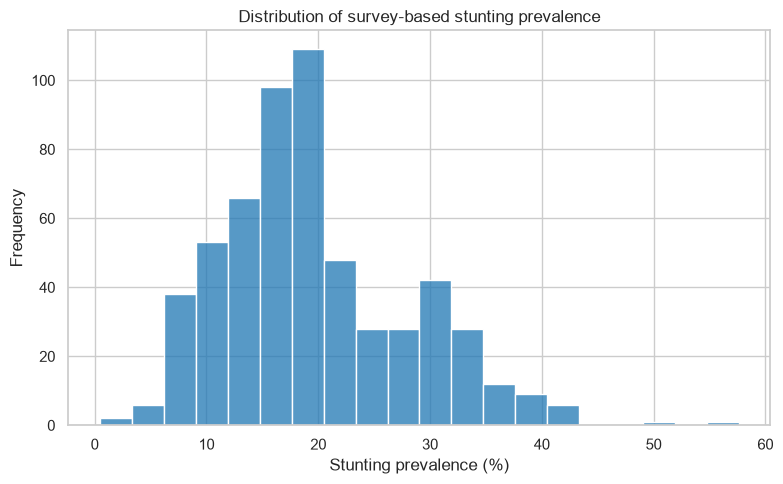

,Prevalence (%)
count,575.000000
mean,19.649739
std,8.345041
min,0.500000
25%,14.350000
50%,18.100000
75%,24.400000
max,57.600000


In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=analysis_df, x="prevalence", bins=20, kde=False, color="#1f77b4")
plt.title("Distribution of survey-based stunting prevalence")
plt.xlabel("Stunting prevalence (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("histogram.png", dpi=300, bbox_inches="tight")
plt.show()

display(analysis_df["prevalence"].describe().to_frame("Prevalence (%)"))

### EDA 2 — Year versus stunting prevalence

The analysis shows a negative relationship between year and stunting prevalence, indicating that prevalence tended to be lower in later years. However, correlation measures a linear relationship between two variables; it does not mean that prevalence declined every year or that the passage of time directly caused the observed changes.

Pearson correlation between year and prevalence: -0.729


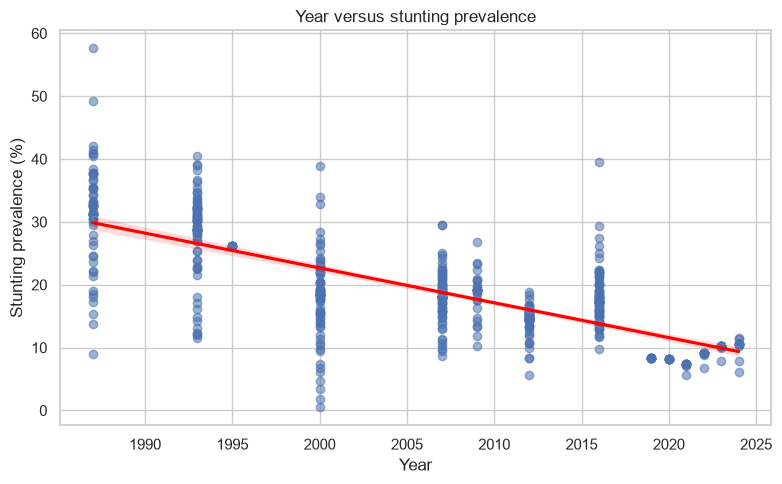

In [15]:
pearson_r = analysis_df[["year", "prevalence"]].corr().loc["year", "prevalence"]
print(f"Pearson correlation between year and prevalence: {pearson_r:.3f}")

plt.figure(figsize=(8, 5))
sns.regplot(data=analysis_df, x="year", y="prevalence",
            scatter_kws={"alpha": 0.55}, line_kws={"color": "red"})
plt.title("Year versus stunting prevalence")
plt.xlabel("Year")
plt.ylabel("Stunting prevalence (%)")
plt.tight_layout()
plt.savefig("scatter.png", dpi=300, bbox_inches="tight")
plt.show()

### EDA 3 — Stunting prevalence by sex

The box plot compares recorded values for Male, Female, and Both sexes categories. Differences in this descriptive plot should not be called statistically significant without considering the hypothesis-test result. “Both sexes” is an aggregate category, not an independent sex group.

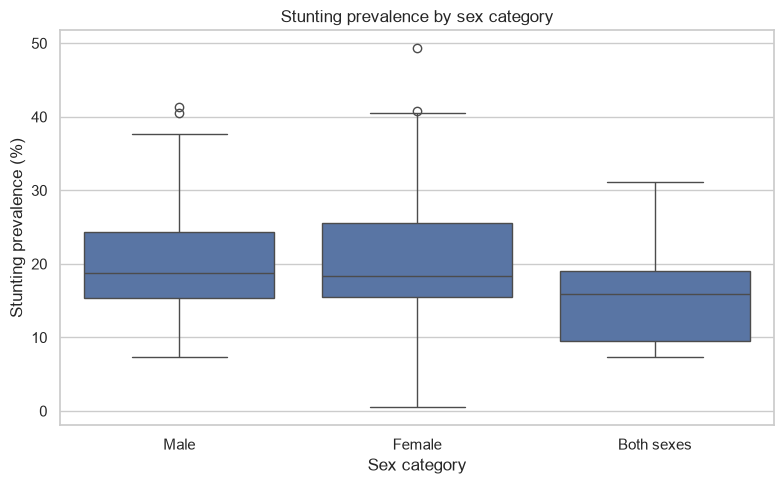

,count,mean,median,std
dimension_name,,,,
Both sexes,14,16.250000,15.95,7.935291
Female,128,20.468750,18.35,8.332790
Male,129,20.706202,18.80,7.293713


In [16]:
sex_data = analysis_df.loc[
    (analysis_df["dimension_type"] == "SEX") &
    (analysis_df["dimension_name"].isin(["Male", "Female", "Both sexes"]))
].copy()

plt.figure(figsize=(8, 5))
sns.boxplot(data=sex_data, x="dimension_name", y="prevalence",
            order=["Male", "Female", "Both sexes"])
plt.title("Stunting prevalence by sex category")
plt.xlabel("Sex category")
plt.ylabel("Stunting prevalence (%)")
plt.tight_layout()
plt.savefig("sex_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

display(sex_data.groupby("dimension_name")["prevalence"].agg(["count", "mean", "median", "std"]))

### EDA 4 — Correlation heatmap

The heatmap shows the relationship among selected numerical fields. `STARTYEAR` and `ENDYEAR` are highly redundant with `year`, so they are excluded from the machine-learning predictors. The year–prevalence correlation in the cleaned subset is approximately −0.729.

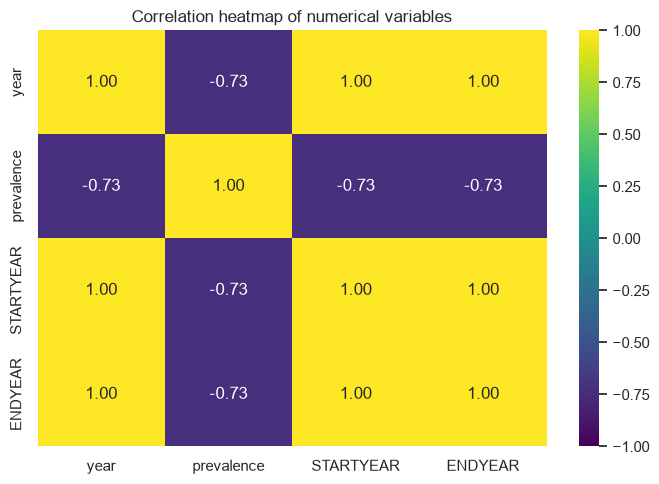

In [17]:
corr_data = analysis_df[["year", "prevalence"]].copy()
# STARTYEAR and ENDYEAR are shown for reference in the report's figure, but are
# excluded from predictors because they are redundant with year.
corr_data["STARTYEAR"] = pd.to_numeric(analysis_df["STARTYEAR"], errors="coerce")
corr_data["ENDYEAR"] = pd.to_numeric(analysis_df["ENDYEAR"], errors="coerce")

plt.figure(figsize=(7, 5))
sns.heatmap(corr_data.corr(numeric_only=True), annot=True, cmap="viridis",
            vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation heatmap of numerical variables")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Hypothesis testing

Both tests use a significance level of **α = 0.05**. The decision rule is:
- If p-value < 0.05, reject H₀.
- If p-value ≥ 0.05, fail to reject H₀.

A p-value above 0.05 means there is insufficient evidence to reject H₀; it does not prove that the population means are identical.

### Test 1 — Welch’s independent-samples t-test: Rural versus Urban

- **H₀:** The mean stunting prevalence in Rural observations equals the mean in Urban observations.
- **H₁:** The two means are different.
- **Test:** Welch’s independent-samples t-test (does not assume equal population variances).

In [10]:
residence_data = analysis_df.loc[
    (analysis_df["dimension_type"] == "RESIDENCEAREATYPE") &
    (analysis_df["dimension_name"].isin(["Rural", "Urban"]))
].copy()

rural = residence_data.loc[residence_data["dimension_name"] == "Rural", "prevalence"].dropna()
urban = residence_data.loc[residence_data["dimension_name"] == "Urban", "prevalence"].dropna()

welch_result = stats.ttest_ind(rural, urban, equal_var=False)

print("H₀: Rural mean prevalence = Urban mean prevalence")
print("H₁: Rural mean prevalence ≠ Urban mean prevalence")
print(f"Rural n={len(rural)}, mean={rural.mean():.3f}")
print(f"Urban n={len(urban)}, mean={urban.mean():.3f}")
print(f"Welch t-statistic = {welch_result.statistic:.3f}")
print(f"p-value = {welch_result.pvalue:.4f}")
print(f"Significance level α = {ALPHA:.2f}")
print("Conclusion:", "Reject H₀." if welch_result.pvalue < ALPHA
      else "Fail to reject H₀; insufficient evidence of a rural–urban mean difference.")

H₀: Rural mean prevalence = Urban mean prevalence
H₁: Rural mean prevalence ≠ Urban mean prevalence
Rural n=11, mean=17.391
Urban n=11, mean=12.382
Welch t-statistic = 1.627
p-value = 0.1212
Significance level α = 0.05
Conclusion: Fail to reject H₀; insufficient evidence of a rural–urban mean difference.


### Test 2 — One-way ANOVA: Male, Female, and Both sexes

*  **Null hypothesis (H₀):** The average stunting prevalence is the same for Male, Female, and Both sexes groups.
*   **Alternative hypothesis (H₁):** At least one group's average prevalence is different.
*   **Test used:** One-way ANOVA.

The “Both sexes” category represents combined data for males and females. Therefore, the results should be interpreted carefully. This test provides an initial comparison of the average prevalence across the three categories, but it does not provide definite evidence of differences in stunting prevalence between males and females in the population.



In [11]:
male = sex_data.loc[sex_data["dimension_name"] == "Male", "prevalence"].dropna()
female = sex_data.loc[sex_data["dimension_name"] == "Female", "prevalence"].dropna()
both = sex_data.loc[sex_data["dimension_name"] == "Both sexes", "prevalence"].dropna()

anova_result = stats.f_oneway(male, female, both)

print("H₀: Mean prevalence is equal for Male, Female, and Both sexes categories")
print("H₁: At least one category mean differs")
print(f"Group sizes: Male={len(male)}, Female={len(female)}, Both sexes={len(both)}")
print(f"ANOVA F-statistic = {anova_result.statistic:.3f}")
print(f"p-value = {anova_result.pvalue:.4f}")
print(f"Significance level α = {ALPHA:.2f}")
print("Conclusion:", "Reject H₀; at least one group mean differs."
      if anova_result.pvalue < ALPHA
      else "Fail to reject H₀; insufficient evidence of a difference among the category means.")

H₀: Mean prevalence is equal for Male, Female, and Both sexes categories
H₁: At least one category mean differs
Group sizes: Male=129, Female=128, Both sexes=14
ANOVA F-statistic = 2.065
p-value = 0.1288
Significance level α = 0.05
Conclusion: Fail to reject H₀; insufficient evidence of a difference among the category means.


## 8. Machine learning models

Two regression models are trained with the same 80:20 split and the same preprocessing:
1. **Linear Regression**
2. **Random Forest Regression**

The target is reported stunting prevalence. The model results are evaluated using:
- **MAE:** average absolute prediction error; lower is better.
- **RMSE:** gives greater weight to larger errors; lower is better.
- **R²:** compares model predictions with a mean-prediction baseline; higher is generally better.

Because this is a random split of subgroup observations, the metrics should not be interpreted as proof of reliable future forecasting.

In [12]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE
    )
}

fitted_models = {}
predictions = {}
results = []

for model_name, estimator in models.items():
    # A separate pipeline ensures preprocessing is fitted only on this model's training data.
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)

    fitted_models[model_name] = model_pipeline
    predictions[model_name] = y_pred
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
        "R²": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

,MAE,RMSE,R²
Model,,,
Linear Regression,3.703,5.027,0.584
Random Forest,3.326,5.713,0.463


**Machine learning model comparison (MAE, RMSE, and R²)**







### Interpreting model performance

Based on the evaluation results, Linear Regression achieves a better overall fit, with lower RMSE and higher R², while Random Forest has a slightly lower MAE. Generally, lower MAE and RMSE values and a higher R² value indicate better model performance. These results suggest that year trends and encoded categories provide useful predictive information.

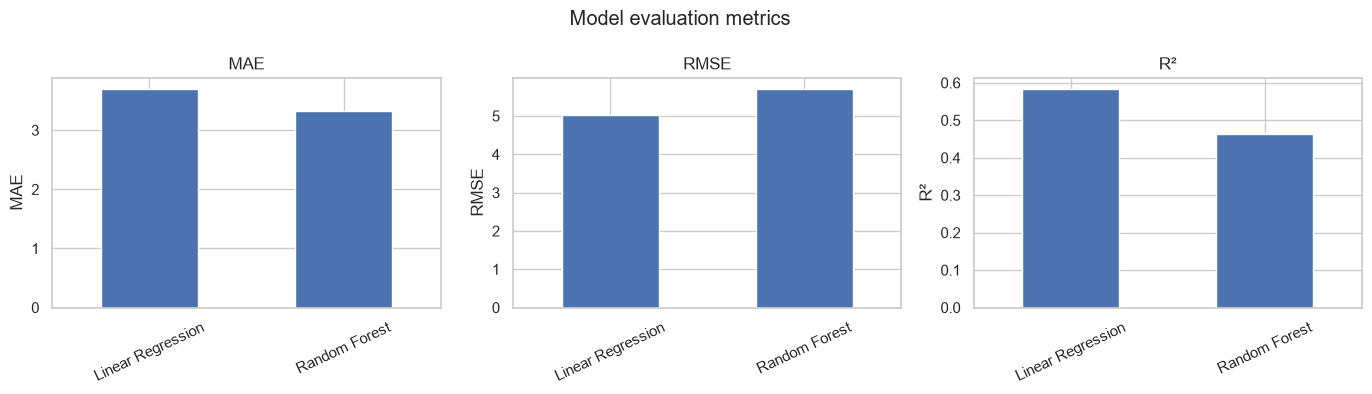

In [13]:
# Visual comparison of the metrics calculated in this notebook.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    results_df[metric].plot(kind="bar", ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel(metric)
plt.suptitle("Model evaluation metrics")
plt.tight_layout()
plt.show()

## 9. Summary of findings

The analysis showed a negative relationship between year and stunting prevalence, meaning that prevalence generally tended to be lower in later years.

Both hypothesis tests were not statistically significant at the 0.05 significance level.

Linear Regression performed better in terms of RMSE and R², while Random Forest achieved a slightly lower MAE.